In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import platform

import torch
import torch.nn as nn
import torch.optim as optim

import sklearn
from sklearn.datasets import load_digits, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

# 데이터를 가져오는 모듈
from torch.utils.data import TensorDataset, DataLoader

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin': # Mac OS
    plt.rc('font', family='AppleGothic')
else: # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

sklearn.set_config(display="text")

# 캘리포니아 하우징 데이터셋

| 컬럼명 | 한글 설명 | 상세 의미 및 단위 |
| --- | --- | --- |
| MedInc | 중간 소득 | 블록 내 가구들의 중간 소득 (단위: 10,000 달러) |
| HouseAge | 주택 연식 | 블록 내 주택들의 평균 건령 (단위: 년) |
| AveRooms | 평균 방 수 | 가구당 평균 방 개수 |
| AveBedrms | 평균 침실 수 | 가구당 평균 침실 개수 |
| Population | 인구수 | 블록 내 전체 거주 인구수 (단위: 명) |
| AveOccup | 평균 거주자 수 | 가구당 평균 거주 인원수 (단위: 명) |
| Latitude | 위도 | 블록 위치의 위도 좌표 (도) |
| Longitude | 경도 | 블록 위치의 경도 좌표 (도) |
| Target | 주택 가격 (정답) | 블록 내 주택 가격 중간값 (단위: 100,000 달러) |

# 1 단계, 데이터 준비

In [11]:
housing = fetch_california_housing()
print(housing)

# 데이터셋을 변수에담기

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
          37.88      , -122.23      ],
       [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
          37.86      , -122.22      ],
       [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
          37.85      , -122.24      ],
       ...,
       [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
          39.43      , -121.22      ],
       [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
          39.43      , -121.32      ],
       [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
          39.37      , -121.24      ]], shape=(20640, 8)), 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)), 'frame': None, 'target_names': ['MedHouseVal'], 'feature_names': ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude'], 'DESCR': '.. _california_housing_dataset

In [16]:
housing_df = pd.DataFrame(
    data=housing.data,
    columns=housing.feature_names
)
housing_df["Target"] = housing.target
# 데이터 프레임을 만들고 컬럼명 지정해주고 타겟은 타겟이라고 이름 따로 지정

In [17]:
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [6]:
housing_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [23]:
# 데이터 나누기
X = housing_df.drop("Target", axis=1)
print(X.head(3))
y = housing_df["Target"]
print(y.head(3))

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
0    4.526
1    3.585
2    3.521
Name: Target, dtype: float64


In [25]:
# 트레인데이터와 테스트 데이터 나누기
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(16512, 8) (4128, 8) (16512,) (4128,)


In [26]:
# 표준화
# 표준화를 하는 이유? -> 
# 숫자의 범위와 단위가 서로 다름, 
# 값의 크기차이 때문에 모델학습이 영향을 받는 것을 줄일 수 있음.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# fit : 훈련 데이터의 평균과 표준편차를 계산
# transform : 계산한 평균과 표준편차를 이용해 데이터를 표준화

In [28]:
# 파이토치의 텐서로 형변환
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).unsqueeze(1)

print(X_train_tensor.shape, y_train_tensor.shape)
print(X_test_tensor.shape, y_test_tensor.shape)

torch.Size([16512, 8]) torch.Size([16512, 1])
torch.Size([4128, 8]) torch.Size([4128, 1])


In [32]:
# 텐서 데이터셋으로 묶기
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [33]:
# 데이터로더를 이용, 베치를 나누어 효율적으로 데이터 공급
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, drop_last=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=True, drop_last=False)

In [44]:
# 배치로 가져와
X_batch, y_batch = next(iter(train_loader))
print(X_batch.shape, y_batch.shape)

torch.Size([64, 8]) torch.Size([64, 1])


# 2 단계, 모델 준비

In [38]:
model = nn.Linear(8, 1)

In [39]:
criterion = nn.MSELoss()

In [40]:
optimizer = optim.SGD(model.parameters(), lr=0.01)

# 3단계, 모델 학습

In [42]:
# 학습모드 설정
model.train()

Linear(in_features=8, out_features=1, bias=True)

In [49]:
# 1 epoch : 훈련데이터 전체를 한번 학습
epoch_loss = 0

for X_batch, y_batch in train_loader:
    optimizer.zero_grad() # 기울기 초기화
    prediction = model(X_batch) # 순전파
    loss = criterion(prediction, y_batch) # 손실 계산
    loss.backward() # 역전파
    optimizer.step() # 재학습 (가중치 업데이트)

    epoch_loss += loss.item()

avg_loss = epoch_loss / len(train_loader)
print(f"1 epoch 학습 완료 ! 평균 Loss : {avg_loss:.4f}")

1 epoch 학습 완료 ! 평균 Loss : 0.5391


In [50]:
# 100 epoch

epochs = 100

for epoch in range(epochs):
    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        prediction = model(X_batch)
        loss = criterion(prediction, y_batch) 
        loss.backward() 
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch: {epoch + 1}/{epochs} | Loss: {avg_loss:.4f}")

Epoch: 10/100 | Loss: 0.5369
Epoch: 20/100 | Loss: 0.5429
Epoch: 30/100 | Loss: 0.5309
Epoch: 40/100 | Loss: 0.5425
Epoch: 50/100 | Loss: 0.5337
Epoch: 60/100 | Loss: 0.5385
Epoch: 70/100 | Loss: 0.5316
Epoch: 80/100 | Loss: 0.5315
Epoch: 90/100 | Loss: 0.5327
Epoch: 100/100 | Loss: 0.5397


# 4 단계, 모델 평가

In [51]:
model.eval()

Linear(in_features=8, out_features=1, bias=True)

In [52]:
test_loss = 0.0

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        prediction = model(X_batch)
        loss = criterion(prediction, y_batch)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_loader)
print(f"Test dataset의 avg loss: {avg_test_loss: .4f}")

Test dataset의 avg loss:  0.5318


In [55]:
# 실제로 집값 예측하게 해보기

# 새로운 집의 정보 8개 넣고 표준화
new_house = pd.DataFrame(
    [[8.3252, 41.0, 6.984127, 1.023810, 322.0, 2.555556, 37.88, -122.23]],
    columns=X_train.columns # 컬럼 없으면 경고 뜨니 컬럼 넣어주기
)
scaled = scaler.transform(new_house)

new_data = torch.tensor(scaled, dtype=torch.float32)

model.eval()

with torch.no_grad():
    prediction = model(new_data) # 새 데이터 넣어서 예측!

    print(f"집값 예측(단위: 100,000 달러): {prediction}")

집값 예측(단위: 100,000 달러): tensor([[4.1634]])


------------------------------------------------------------------------------------------------

# 손 글씨 숫자 데이터 셋

## 손글씨 데이터 컬럼
| 키 (Key/Column) | 데이터 타입 | 데이터 형태 (Shape) | 설명 |
| :--- | :--- | :--- | :--- |
| **`data`** | `ndarray` (float64) | `(1797, 64)` | 모델 학습에 사용되는 **입력 데이터**입니다. 8x8 픽셀 이미지를 1차원으로 길게 펼친 64개의 특징(Feature) 값이 1,797개 들어 있습니다. |
| **`target`** | `ndarray` (int64) | `(1797,)` | 모델이 맞춰야 하는 **정답(라벨) 데이터**입니다. 각 이미지에 해당하는 숫자(0~9)가 매칭되어 있습니다. |
| **`feature_names`** | `list` (str) | `64개 항목` | `data`의 64개 열이 어떤 픽셀을 의미하는지 나타내는 이름입니다. 행과 열을 기준으로 `pixel_0_0`부터 `pixel_7_7`까지 명명되어 있습니다. |
| **`target_names`** | `ndarray` (int64) | `(10,)` | 정답이 클래스로서 가질 수 있는 실제 값의 종류인 `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`를 의미합니다. |
| **`images`** | `ndarray` (float64) | `(1797, 8, 8)` | `data`와 동일한 픽셀 값이지만, 펼치지 않고 **원본 8x8 행렬 형태**를 유지한 데이터입니다. `matplotlib` 등으로 시각화할 때 주로 씁니다. |
| **`DESCR`** | `str` | 텍스트 원문 | 데이터셋의 출처, 데이터 수집 방식, 픽셀 값 범위(0~16) 등 데이터셋에 대한 **상세한 설명(Description)**이 담긴 영문 텍스트입니다. |
| **`frame`** | `NoneType` 또는 `DataFrame` | 변동 가능 | 데이터를 판다스(Pandas)의 DataFrame 구조로 불러오지 않았다면 기본적으로 `None`으로 표시됩니다. |

# 1 단계, 데이터 준비

In [57]:
digits = load_digits()
digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7'

In [61]:
X = digits["data"]
y = digits["target"]

In [62]:
print(X.shape, y.shape)

(1797, 64) (1797,)


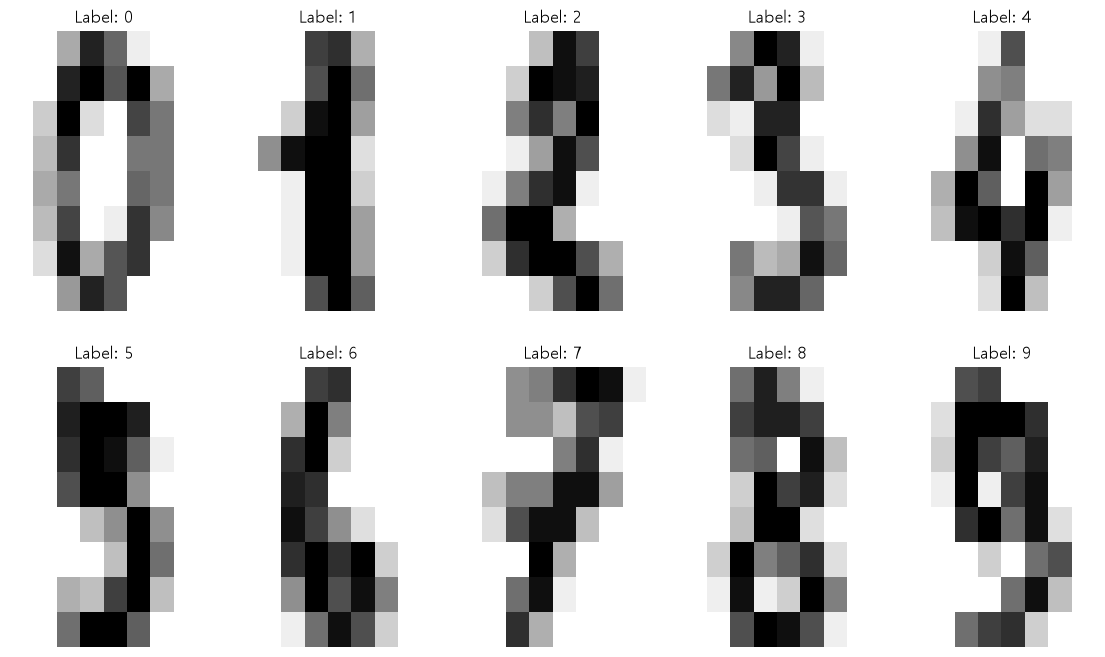

In [70]:
fig, axes = plt.subplots(2, 5, figsize=(14, 8))

for i, ax in enumerate(axes.flatten()):
    img_data = X[i].reshape((8, 8))
    sns.heatmap(img_data, cmap="gray_r", cbar=False, ax=ax, xticklabels=False, yticklabels=False)
    ax.set_title(f"Label: {y[i]}")

plt.show()

In [71]:
# 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=2026)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1437, 64) (360, 64) (1437,) (360,)


In [73]:
#정규화 # MinMaxScaler()
X_train_tensor = torch.tensor(X_train, dtype=torch.float) / 16.0
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float) / 16.0
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

In [74]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [75]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [80]:
imgs, labels = next(iter(train_loader))
print(imgs.shape, labels.shape)

torch.Size([64, 64]) torch.Size([64])


# 2 단계, 모델 준비

In [81]:
model = nn.Sequential(nn.Linear(64,10))
model

Sequential(
  (0): Linear(in_features=64, out_features=10, bias=True)
)

In [82]:
criterion = nn.CrossEntropyLoss() # 모델이 숫자를 얼마나 틀렸는지 계산하는 손실 함수
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3 단계, 모델 학습

In [86]:
epochs = 50

model.train()

for epoch in range(epochs):
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad() # 기울기 초기화
        y_pred = model(X_batch) # 순전파
        loss = criterion(y_pred, y_batch) # 손실 계산
        loss.backward() # 역전파
        optimizer.step() # 가중치 업데이트

        sum_losses += loss.item()

        #정확도 계산
        y_pred_index = y_pred.argmax(dim=1) # argmax()는 가장 큰 값이 있는 위치(인덱스)를 찾는 함수
        acc = (y_batch == y_pred_index).float().mean().item() * 100

        sum_accs += acc

    avg_train_loss = sum_losses / len(train_loader)
    avg_train_acc = sum_accs / len(train_loader)

    print(f"Epoch: {epoch + 1}/{epochs} | Train Loss: {avg_train_loss:.4f}, Train Acc: {avg_train_acc:.2f}%")

Epoch: 1/50 | Train Loss: 0.2312, Train Acc: 95.41%
Epoch: 2/50 | Train Loss: 0.2304, Train Acc: 95.43%
Epoch: 3/50 | Train Loss: 0.2298, Train Acc: 95.49%
Epoch: 4/50 | Train Loss: 0.2235, Train Acc: 95.42%
Epoch: 5/50 | Train Loss: 0.2234, Train Acc: 95.47%
Epoch: 6/50 | Train Loss: 0.2211, Train Acc: 95.49%
Epoch: 7/50 | Train Loss: 0.2192, Train Acc: 95.42%
Epoch: 8/50 | Train Loss: 0.2210, Train Acc: 95.49%
Epoch: 9/50 | Train Loss: 0.2156, Train Acc: 95.56%
Epoch: 10/50 | Train Loss: 0.2117, Train Acc: 95.92%
Epoch: 11/50 | Train Loss: 0.2149, Train Acc: 95.61%
Epoch: 12/50 | Train Loss: 0.2081, Train Acc: 95.86%
Epoch: 13/50 | Train Loss: 0.2085, Train Acc: 95.77%
Epoch: 14/50 | Train Loss: 0.2072, Train Acc: 95.91%
Epoch: 15/50 | Train Loss: 0.2106, Train Acc: 95.81%
Epoch: 16/50 | Train Loss: 0.2047, Train Acc: 95.90%
Epoch: 17/50 | Train Loss: 0.2065, Train Acc: 95.90%
Epoch: 18/50 | Train Loss: 0.2008, Train Acc: 96.18%
Epoch: 19/50 | Train Loss: 0.1995, Train Acc: 96.25%
Ep

# 4 단계, 모델 평가

In [88]:
model.eval()

test_loss = 0.0
test_acc = 0.0

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        y_test_pred = model(X_batch)
        loss = criterion(y_test_pred, y_batch)
        test_loss += loss.item()
        
        y_test_index = y_test_pred.argmax(dim=1)
        acc = (y_batch == y_test_index).float().mean().item() * 100
        test_acc += acc

avg_test_loss = test_loss / len(test_loader)
avg_test_acc = test_acc / len(test_loader)

print(f"최종 Test 결과 | Loss {avg_test_loss:.4f}, Accuracy: {avg_test_acc:.2f}")

최종 Test 결과 | Loss 0.1866, Accuracy: 96.88


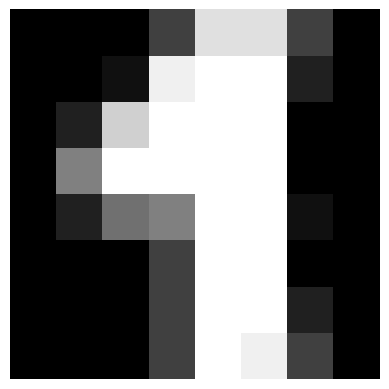

In [89]:
plt.imshow(X_batch[0].reshape((8, 8)), cmap="gray")
plt.axis("off")
plt.show()

In [96]:
# 모델아 예측해봐
model.eval()

X_test_batch, y_test_batch = next(iter(test_loader))

In [97]:
with torch.no_grad():
    y_pred_batch = model(X_test_batch)

print(y_pred_batch[0])
print(y_pred_batch[0].argmax())

tensor([-2.2849e+00,  1.5131e+00, -2.4401e+00,  2.6589e-03, -3.2120e+00,
        -2.3903e+00, -3.8801e+00, -3.6033e+00, -5.4955e-01,  1.7287e+00])
tensor(9)


In [98]:
# 9??? 틀림.

-----------------------------------------------------------------------------------

# Fashion-MNIST
- 28x28 크기의 흑백 이미지 60,000장으로 구성된 10개 클래스의 의류 데이터셋

### Fashion-MNIST 클래스 라벨 설명 (Class Labels)
| 라벨 (Label) | 클래스명 (Class Name) | 설명 (Description) |
| --- | --- | --- |
| 0 | T-shirt/top | 티셔츠 / 상의 |
| 1 | Trouser | 바지 |
| 2 | Pullover | 풀오버 (스웨터) |
| 3 | Dress | 드레스 / 원피스 |
| 4 | Coat | 코트 |
| 5 | Sandal | 샌들 |
| 6 | Shirt | 셔츠 |
| 7 | Sneaker | 스니커즈 / 운동화 |
| 8 | Bag | 가방 |
| 9 | Ankle boot | 앵클부츠 |